# Part I — Questions 4–5: housing regression and KRR


Scope: one shared filtered housing dataset, consistent outer splits and a final comparison.

The report PDF contains the assessed answers; this notebook contains the supporting implementation and experiment outputs.


## Setup and reproducibility

Importing the necessary libraries and setting the Numpy seed. Also, the CSV dataset is located following the repository's structure and is ready to load using Pandas.


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(0)

cwd = Path.cwd()
repo_root = next(
    (folder for folder in (cwd, *cwd.parents)
     if (folder / "data" / "Boston-filtered.csv").is_file()),
    None,
)

csv_path = repo_root / "data" / "Boston-filtered.csv"

## Shared data and experimental setup

Loading the filtered CSV; it contains 506 rows, 12 attributes and a target.


In [ ]:
df = pd.read_csv(csv_path)
df.head()


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2


In [12]:
df.describe()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,37.970000,50.000000


Creating helper functions to preprocess the data: splitting into train and test sets, and decomposing each one into X matrix and Y vector.

In [16]:
def get_split(df, train_size=2/3):
    """
    Splits the dataframe into training and testing sets.
    
    Parameters:
    df (pd.DataFrame): The input dataframe to split.
    train_size (float): The proportion of the dataset to include in the train split.
    
    Returns:
    pd.DataFrame, pd.DataFrame: Training and testing dataframes.
    """
    
    shuffled_indices = np.random.permutation(len(df))
    train_set_size = int(len(df) * train_size)
    
    train_indices = shuffled_indices[:train_set_size]
    test_indices = shuffled_indices[train_set_size:]
    
    return df.iloc[train_indices], df.iloc[test_indices]

In [15]:
def decompose_split(train, test):
    """
    Decomposes the training and testing dataframes into features and target.
    
    Parameters:
    train (pd.DataFrame): The training dataframe.
    test (pd.DataFrame): The testing dataframe.
    
    Returns:
    pd.DataFrame, pd.Series, pd.DataFrame, pd.Series: Features and target for training and testing sets.
    """
    
    X_train = train.drop(columns='MEDV')
    y_train = train['MEDV']
    
    X_test = test.drop(columns='MEDV')
    y_test = test['MEDV']
    
    return X_train, y_train, X_test, y_test

In [21]:
def calculate_mse(y_true, y_pred):
    """
    Calculates the Mean Squared Error (MSE) between true and predicted values.
    
    Parameters:
    y_true (pd.Series): The true target values.
    y_pred (pd.Series): The predicted target values.
    
    Returns:
    float: The MSE value.
    """
    
    return np.sum((y_true - y_pred) ** 2)/len(y_true)

## Question 4(a) — Naive regression

Fit with a column of ones; record training/test MSE for the prescribed random splits.


In [24]:
def naive_regression(df):
    train, test = get_split(df)
    X_train, y_train, X_test, y_test = decompose_split(train, test)

    X_ones_train = np.ones((X_train.shape[0], 1))
    X_ones_test = np.ones((X_test.shape[0], 1))

    w = np.linalg.lstsq(X_ones_train, y_train)[0]
    y_pred_train = X_ones_train @ w
    y_pred_test = X_ones_test @ w

    mse_train = calculate_mse(y_train, y_pred_train)
    mse_test = calculate_mse(y_test, y_pred_test)

    return mse_train, mse_test, w


In [25]:
mse_train_list = []
mse_test_list = []
w_list = []

for i in range(20):
    mse_train, mse_test, w = naive_regression(df)
    mse_train_list.append(mse_train)
    mse_test_list.append(mse_test)
    w_list.append(w)

mse_train_mean = np.mean(mse_train_list)
mse_test_mean = np.mean(mse_test_list)
w_mean = np.mean(w_list)


print(f"Mean MSE for training set: {mse_train_mean}")
print(f"Mean MSE for test set: {mse_test_mean}")
print(f"Mean weight: {w_mean}")

Mean MSE for training set: 83.60626965985436
Mean MSE for test set: 86.26795522733332
Mean weight: 22.524985163204743


## Question 4(b) - Interpretation

The naive regression model predicts the median house price with the function:

$f(x)=22.5$

To understand the resulting function we must understand the way the weight of the Naive Regression was obtained. 

The model is set up as follows:
- $w$ is the weight, resulting value from the regression
- $A$ is the vector of ones.
- $Y$ is the real median house values from the training set.

The model is the solution to the system of linear equations:
$Aw=Y$

Using the least squares solution:

$\hat{w} = (A^TA)^{-1}A^TY=\frac{A^TY}{||A||^2}$

Since $A$ y $Y$ are vectors, then $A^TY=A\cdot Y$. Since $A$ is a vector of ones, $A\cdot Y = \sum_{i}y_i$ 

Then, $\hat{w}$ ends up being the mean of the elements of the target vector $Y$.



## Question 4(c) — Individual attributes

Implement twelve single-attribute regressions, each with a bias. Record train/test MSEs.


In [ ]:
def linear_regression_single_attribute(df, attribute):
    """
    Performs linear regression using a single attribute and returns the MSE for training and testing sets.
    
    Parameters:
    df (pd.DataFrame): The input dataframe.
    attribute (int): The attribute to use for regression.
    
    Returns:
    float, float: MSE for training and testing sets.
    np.ndarray: The weights of the linear regression model.
    """
    
    train, test = get_split(df)
    X_train, y_train, X_test, y_test = decompose_split(train, test)
    X_train = X_train[[attribute]].values
    X_test = X_test[[attribute]].values
    
    # Add a bias term (intercept)
    X_train_with_bias = np.hstack([X_train, np.ones((X_train.shape[0], 1))])
    X_test_with_bias = np.hstack([X_test, np.ones((X_test.shape[0], 1))])
    
    # Calculate weights using the least squares solution
    w = np.linalg.lstsq(X_train_with_bias.T @ X_train_with_bias, X_train_with_bias.T @ y_train)[0]
    
    # Make predictions
    y_pred_train = X_train_with_bias @ w
    y_pred_test = X_test_with_bias @ w
    
    # Calculate MSE
    mse_train = calculate_mse(y_train, y_pred_train)
    mse_test = calculate_mse(y_test, y_pred_test)
    
    return mse_train, mse_test, w

In [64]:
mse_train_list = []
mse_test_list = []
w_list = []

for i in range(len(df.columns) - 1):
    mse_train_attribute_list = []
    mse_test_attribute_list = []
    w_attribute_list = []

    for j in range(20):
        mse_train, mse_test, w = linear_regression_single_attribute(df, df.columns[i])
        mse_train_attribute_list.append(mse_train)
        mse_test_attribute_list.append(mse_test)
        w_attribute_list.append(w)

    mse_train_list.append(np.mean(mse_train_attribute_list))
    mse_test_list.append(np.mean(mse_test_attribute_list))
    w_list.append(np.mean(w_attribute_list, axis=0))

In [65]:
for i in range(len(df.columns) - 1):
    print(f"Attribute: {df.columns[i]}")
    print(f"Mean MSE for training set: {mse_train_list[i]}")
    print(f"Mean MSE for test set: {mse_test_list[i]}")
    print(f"Mean weights: {w_list[i]}")
    print()

Attribute: CRIM
Mean MSE for training set: 71.15727508031848
Mean MSE for test set: 73.53315643374084
Mean weights: [-0.43301547 24.03216331]

Attribute:  ZN 
Mean MSE for training set: 75.83195394561139
Mean MSE for test set: 69.01261723191296
Mean weights: [ 0.1410052  21.03001412]

Attribute: INDUS 
Mean MSE for training set: 63.2032079209911
Mean MSE for test set: 68.25237661503041
Mean weights: [-0.65761045 29.79914191]

Attribute: CHAS
Mean MSE for training set: 79.75503395243092
Mean MSE for test set: 86.4867928894057
Mean weights: [ 6.90187479 22.10099586]

Attribute: NOX
Mean MSE for training set: 69.07107072054987
Mean MSE for test set: 69.20517389039728
Mean weights: [-33.4774508  41.0751254]

Attribute: RM
Mean MSE for training set: 42.23956517497621
Mean MSE for test set: 46.765627780836496
Mean weights: [  9.20876573 -35.39871685]

Attribute: AGE
Mean MSE for training set: 71.63056046601831
Mean MSE for test set: 74.45748062349386
Mean weights: [-0.12618638 31.2113191 ]



## Question 4(d) — All attributes

Fit all attributes plus bias and record train/test MSEs.


In [31]:
def full_linear_regression(df):
    """
    Performs linear regression using all attributes and returns the MSE for training and testing sets.
    
    Parameters:
    df (pd.DataFrame): The input dataframe.
    
    Returns:
    float, float: MSE for training and testing sets.
    np.ndarray: The weights of the linear regression model.
    """
    
    train, test = get_split(df)
    X_train, y_train, X_test, y_test = decompose_split(train, test)
    
    # Add a bias term (intercept)
    X_train_with_bias = np.hstack([X_train.values, np.ones((X_train.shape[0], 1))])
    X_test_with_bias = np.hstack([X_test.values, np.ones((X_test.shape[0], 1))])
    
    # Calculate weights using the least squares solution
    w = np.linalg.lstsq(X_train_with_bias.T @ X_train_with_bias, X_train_with_bias.T @ y_train)[0]
    
    # Make predictions
    y_pred_train = X_train_with_bias @ w
    y_pred_test = X_test_with_bias @ w
    
    # Calculate MSE
    mse_train = calculate_mse(y_train, y_pred_train)
    mse_test = calculate_mse(y_test, y_pred_test)
    
    return mse_train, mse_test, w

In [66]:
mse_train_list = []
mse_test_list = []
w_list = []

for i in range(20):
    mse_train, mse_test, w = full_linear_regression(df)
    mse_train_list.append(mse_train)
    mse_test_list.append(mse_test)
    w_list.append(w)

mse_train_mean = np.mean(mse_train_list)
mse_test_mean = np.mean(mse_test_list)

In [67]:
print(f"Mean MSE for training set: {mse_train_mean}")
print(f"Mean MSE for test set: {mse_test_mean}")

Mean MSE for training set: 22.536979550325466
Mean MSE for test set: 23.40352857162154


# Question 5 - Kernelised Ridge Regression

Helper functions to compute the kernel function and build the appropriate Kernel Matrix.

In [42]:
def kernel_function(x1, x2, sigma):
    """
    Computes the kernel between two data points.
    
    Parameters:
    x1 (np.ndarray): First data point.
    x2 (np.ndarray): Second data point.
    sigma (float)
    
    Returns:
    float: The computed kernel value.
    """
    
    return np.exp(-np.linalg.norm(x1 - x2)**2 / (2 * sigma**2))

In [48]:
def construct_kernel_matrix(x, sigma, x_reference=None):
    """
    Constructs the kernel matrix.
    
    Parameters:
    x (np.ndarray): The input data points.
    sigma (float)
    Returns:
    np.ndarray: The kernel matrix.
    """
    
    if x_reference is None:
        x_reference = x

    K = np.zeros((len(x), len(x_reference)))

    for i in range(len(x)):
        for j in range(len(x_reference)):
            K[i, j] = kernel_function(x[i], x_reference[j], sigma)
    
    return K

## Question 5(a) — Five-fold cross-validation

This question involves the implementation of the Kernel Ridge Regression. Also, it performs a search over the vectors $\gamma=\{2^{-40}, 2^{-39}, \dots, 2^{-26}\}$ and $\sigma=\{2^{7}, 2^{7.5}, \dots, 2^{13}\}$ to find the ones that best fit the data in the KRR using 5-fold cross validation.

When the besst $\gamma$ and $\sigma$ are found, the model is retrained with them on the full training set to get the best weights possible for KRR.




In [41]:
def create_gamma_vector():
    gamma_array = [2**i for i in range(-40, -25)]
    gamma = np.array(gamma_array)
    return gamma

In [39]:
def create_sigma_vector():
    sigma = 2.0 ** np.arange(7, 13.5, 0.5)
    return sigma

In [54]:
def kernel_ridge_regression_cross_validation(df, folds=5):
    """
    Performs kernel ridge regression and returns the MSE for training and testing sets.
    
    Parameters:
    df (pd.DataFrame): The input dataframe.
    folds (int): The number of folds for cross-validation.
    Returns:
    float, float: MSE for training and testing sets.
    np.ndarray: The weights of the kernel ridge regression model.
    """
    
    train, test = get_split(df)
    X_train, y_train, X_test, y_test = decompose_split(train, test)
    
    # Create sigma and gamma vectors
    sigma_vector = create_sigma_vector()
    gamma_vector = create_gamma_vector()
    
    # Initialize lists to store MSE values
    mse_train_list = []
    mse_cross_val_list = []

    for sigma in sigma_vector:
        for gamma in gamma_vector:

            mse_fold_list = []
            w_fold_list = []

            for fold in range(folds):
                # Split the training data into training and validation sets for cross-validation
                fold_size = len(X_train) // folds
                start = fold * fold_size
                end = start + fold_size if fold != folds - 1 else len(X_train)

                # Create training and validation sets for the current fold
                X_train_fold = np.delete(X_train.values, np.s_[start:end], axis=0)
                y_train_fold = np.delete(y_train.values, np.s_[start:end], axis=0)
                X_val_fold = X_train.values[start:end]
                y_val_fold = y_train.values[start:end]

                # Construct kernel matrices for training and validation sets
                K_train_fold = construct_kernel_matrix(X_train_fold, sigma)
                K_val_fold = construct_kernel_matrix(X_val_fold, sigma, X_train_fold)

                # Calculate weights using the kernel ridge regression formula
                w = np.linalg.lstsq(K_train_fold + gamma * len(X_train_fold) * np.eye(K_train_fold.shape[0]), y_train_fold, rcond=None)[0]
            
                # Make predictions
                y_pred_val = K_val_fold @ w
            
                # Calculate MSE
                mse_val = calculate_mse(y_val_fold, y_pred_val)
                mse_fold_list.append(mse_val)

            # Average MSE and weights across folds
            mse_train_list.append(np.mean(mse_fold_list))
            mse_cross_val_list.append(np.mean(mse_fold_list))

    index_min_mse = np.argmin(mse_train_list)
    best_sigma = sigma_vector[index_min_mse // len(gamma_vector)]
    best_gamma = gamma_vector[index_min_mse % len(gamma_vector)]

    return np.mean(mse_train_list), (best_sigma, best_gamma), mse_cross_val_list

In [58]:
mse_train_mean, (best_sigma, best_gamma), _ = kernel_ridge_regression_cross_validation(df)

print(f"Mean MSE for training set: {mse_train_mean}")
best_sigma_log = np.log2(best_sigma)
best_gamma_log = np.log2(best_gamma)
print(f"Best sigma: {best_sigma} (log2: {best_sigma_log}), Best gamma: {best_gamma} (log2: {best_gamma_log})")

Mean MSE for training set: 51.48762778115979
Best sigma: 362.03867196751236 (log2: 8.5), Best gamma: 1.4901161193847656e-08 (log2: -26.0)


## Question 5(b) — Cross-validation error plot

Plot the mean fold-validation error over the gamma/sigma grid. Label any logarithmic parameter scales explicitly.


In [56]:
def plot_mse_cross_val(mse_cross_val_list, sigma_vector, gamma_vector):
    """
    Plots the MSE values from cross-validation.
    
    Parameters:
    mse_cross_val_list (list): List of MSE values from cross-validation.
    sigma_vector (np.ndarray): Array of sigma values.
    gamma_vector (np.ndarray): Array of gamma values.
    """
    
    mse_matrix = np.array(mse_cross_val_list).reshape(len(sigma_vector), len(gamma_vector))
    
    plt.figure(figsize=(10, 6))
    plt.imshow(mse_matrix, aspect='auto', origin='lower', extent=[np.log2(gamma_vector[0]), np.log2(gamma_vector[-1]), np.log2(sigma_vector[0]), np.log2(sigma_vector[-1])])
    plt.colorbar(label='MSE')
    plt.xlabel('Gamma (log2 scale)')
    plt.ylabel('Sigma (log2 scale)')
    plt.title('MSE Cross-Validation Heatmap')
    plt.show()

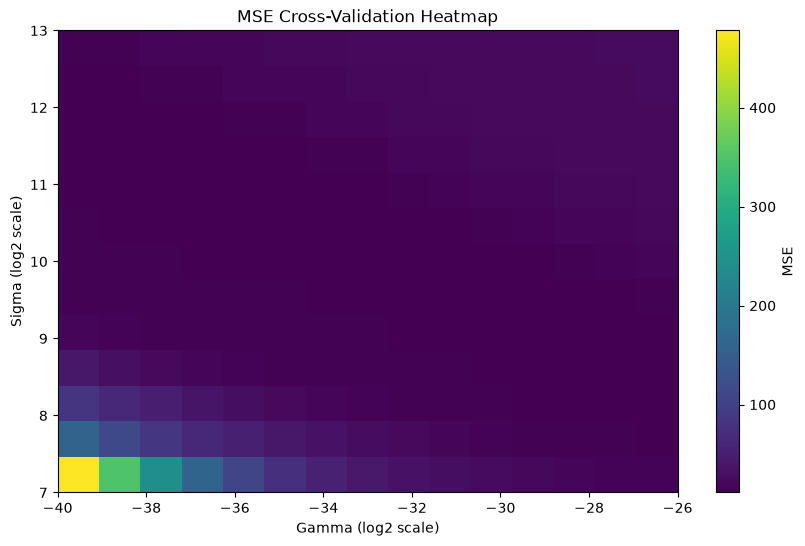

In [57]:
_, _, mse_cross_val_list = kernel_ridge_regression_cross_validation(df)
plot_mse_cross_val(mse_cross_val_list, create_sigma_vector(), create_gamma_vector())

## Question 5(c) — Selected-model errors

Record the best pair and its retrained training/test MSEs.


In [ ]:
def kernel_ridge_regression(df, sigma, gamma):
    """
    Performs kernel ridge regression on the entire dataset given the best gamma and sigma
    and returns the MSE for training and testing sets.
    
    Parameters:
    df (pd.DataFrame): The input dataframe.
    
    Returns:
    float, float: MSE for training and testing sets.
    np.ndarray: The weights of the kernel ridge regression model.
    """
    
    train, test = get_split(df)
    X_train, y_train, X_test, y_test = decompose_split(train, test)
    
    # Construct kernel matrices for training and testing sets
    K_train = construct_kernel_matrix(X_train.values, sigma)
    K_test = construct_kernel_matrix(X_test.values, sigma, X_train.values)

    # Calculate weights using the kernel ridge regression formula
    w = np.linalg.lstsq(K_train + gamma * len(X_train) * np.eye(K_train.shape[0]), y_train, rcond=None)[0]

    # Make predictions
    y_pred_train = K_train @ w
    y_pred_test = K_test @ w

    # Calculate MSE
    mse_train = calculate_mse(y_train, y_pred_train)
    mse_test = calculate_mse(y_test, y_pred_test)

    return mse_train, mse_test, w
    

In [60]:
mse_train, mse_test, w = kernel_ridge_regression(df, best_sigma, best_gamma)
print(f"MSE for training set: {mse_train}")
print(f"MSE for test set: {mse_test}")

MSE for training set: 8.646694801010819
MSE for test set: 10.351972771446016


## Question 5(d) — Comparison over 20 splits

This question involves creating a summary of all the MSEs (train and test data) for points 4 (a, c, and d) and 5 (a, c). Each question's process must be performed over 20 random different splits of the data and the resulting table must contain the means of the model's MSE and its standard deviations. 


In [61]:
naive_mse_train_list = []
naive_mse_test_list = []
single_attribute_mse_train_list = [[] for _ in range(len(df.columns) - 1)]
single_attribute_mse_test_list = [[] for _ in range(len(df.columns) - 1)]
full_mse_train_list = []
full_mse_test_list = []
krr_train_mse_list = []
krr_test_mse_list = []

for i in range(20):
    # Naive regression
    mse_train, mse_test, _ = naive_regression(df)
    naive_mse_train_list.append(mse_train)
    naive_mse_test_list.append(mse_test)

    # Single attribute regression
    for j in range(len(df.columns) - 1):
        mse_train, mse_test, _ = linear_regression_single_attribute(df, df.columns[j])
        single_attribute_mse_train_list[j].append(mse_train)
        single_attribute_mse_test_list[j].append(mse_test)

    # Full linear regression
    mse_train, mse_test, _ = full_linear_regression(df)
    full_mse_train_list.append(mse_train)
    full_mse_test_list.append(mse_test)

    # Kernel ridge regression
    _, (best_sigma, best_gamma), _ = kernel_ridge_regression_cross_validation(df)
    mse_train, mse_test, _ = kernel_ridge_regression(df, best_sigma, best_gamma)
    krr_train_mse_list.append(mse_train)
    krr_test_mse_list.append(mse_test)

In [62]:
# Reporting the mean MSE and standard deviation for each method

print("Naive Regression:")
print(f"Mean MSE for training set: {np.mean(naive_mse_train_list)}, Std: {np.std(naive_mse_train_list)}")
print(f"Mean MSE for test set: {np.mean(naive_mse_test_list)}, Std: {np.std(naive_mse_test_list)}")

print("Single Attribute Regression:")
for i in range(len(df.columns) - 1):
    print(f"Attribute: {df.columns[i]}")
    print(f"Mean MSE for training set: {np.mean(single_attribute_mse_train_list[i])}, Std: {np.std(single_attribute_mse_train_list[i])}")
    print(f"Mean MSE for test set: {np.mean(single_attribute_mse_test_list[i])}, Std: {np.std(single_attribute_mse_test_list[i])}")

print("Full Linear Regression:")
print(f"Mean MSE for training set: {np.mean(full_mse_train_list)}, Std: {np.std(full_mse_train_list)}")
print(f"Mean MSE for test set: {np.mean(full_mse_test_list)}, Std: {np.std(full_mse_test_list)}")

print("Kernel Ridge Regression:")
print(f"Mean MSE for training set: {np.mean(krr_train_mse_list)}, Std: {np.std(krr_train_mse_list)}")
print(f"Mean MSE for test set: {np.mean(krr_test_mse_list)}, Std: {np.std(krr_test_mse_list)}")

Naive Regression:
Mean MSE for training set: 84.10867654905829, Std: 3.669024951175678
Mean MSE for test set: 85.30957901254514, Std: 7.233465485279401
Single Attribute Regression:
Attribute: CRIM
Mean MSE for training set: 72.9027012435261, Std: 3.066551923828241
Mean MSE for test set: 70.90365866934123, Std: 6.83304417120112
Attribute:  ZN 
Mean MSE for training set: 73.11646649701797, Std: 4.223349118219728
Mean MSE for test set: 74.35696906968141, Std: 8.437445898280197
Attribute: INDUS 
Mean MSE for training set: 64.89312692108021, Std: 3.663345158723006
Mean MSE for test set: 64.59987740264782, Std: 7.235771750031385
Attribute: CHAS
Mean MSE for training set: 80.72857627181668, Std: 5.459989348685341
Mean MSE for test set: 84.74963043972062, Std: 10.865738736630483
Attribute: NOX
Mean MSE for training set: 69.19377130961922, Std: 5.125365036125494
Mean MSE for test set: 69.15829492158379, Std: 10.234574765568437
Attribute: RM
Mean MSE for training set: 42.710484083374595, Std: 3.